In [1]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense,Dropout,MaxPool2D,GlobalAveragePooling2D
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.models import load_model

I0000 00:00:1789050915.021271     794 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789050916.014297     794 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789050919.153809     794 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
training_path = "../Datasets/data/train/Medical/X-Ray/chest x-ray/train"
testing_path = "../Datasets/data/test/Medical/X-Ray/chest x-ray/test"
valid_path = "../Datasets/data/vaild/Medical/X-Ray/chest x-ray/val"

In [ ]:
train_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    rotation_range = 10,
    zoom_range = 0.2,
    horizontal_flip = True
)
test_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)
valid_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

In [4]:
training_set = train_dataug.flow_from_directory(
    training_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)
valid_set = valid_dataug.flow_from_directory(
    valid_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)
testing_set = test_dataug.flow_from_directory(
    testing_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary",
    shuffle = False
)

Found 8075 images belonging to 2 classes.
Found 1006 images belonging to 2 classes.
Found 1550 images belonging to 2 classes.


In [5]:
base_model = EfficientNetV2B0(weights="imagenet",include_top=False,input_shape=(224,224,3))

I0000 00:00:1789050926.395137     794 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
base_model.trainable = False

In [7]:
base_model.output

<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_269>

In [8]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512,activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu')(x)
output = Dense(1,activation="sigmoid")(x)

In [9]:
model = Model(inputs = base_model.input,outputs = output)

In [10]:
model.compile(optimizer=Adam(learning_rate=0.002),metrics=["accuracy"],loss="binary_crossentropy")

In [11]:
early_stop = EarlyStopping(monitor="loss",patience=5,restore_best_weights=True)

In [12]:
history = model.fit(training_set,validation_data=(valid_set),epochs=20,callbacks=[early_stop])

Epoch 1/20


I0000 00:00:1789050930.665130     794 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1789050936.902268    1219 service.cc:153] XLA service 0x7d4d64036de0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1789050936.902313    1219 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1789050937.417605    1219 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1789050939.530304    1219 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1789050940.173166    1219 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_19149__.265
I0000 00:00:1789050965.664192    1219 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


225/505 ━━━━━━━━━━━━━━━━━━━━ 1:23 297ms/step - accuracy: 0.7758 - loss: 0.4850

I0000 00:00:1789051035.093844    1221 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_19149__.265


505/505 ━━━━━━━━━━━━━━━━━━━━ 241s 409ms/step - accuracy: 0.8747 - loss: 0.3048 - val_accuracy: 0.9503 - val_loss: 0.1891
Epoch 2/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 166s 329ms/step - accuracy: 0.9172 - loss: 0.2226 - val_accuracy: 0.9503 - val_loss: 0.1282
Epoch 3/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 134s 265ms/step - accuracy: 0.9262 - loss: 0.1902 - val_accuracy: 0.9652 - val_loss: 0.1299
Epoch 4/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 137s 272ms/step - accuracy: 0.9335 - loss: 0.1822 - val_accuracy: 0.9652 - val_loss: 0.1017
Epoch 5/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 146s 288ms/step - accuracy: 0.9371 - loss: 0.1682 - val_accuracy: 0.9553 - val_loss: 0.0999
Epoch 6/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 145s 286ms/step - accuracy: 0.9418 - loss: 0.1656 - val_accuracy: 0.9592 - val_loss: 0.1118
Epoch 7/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 146s 290ms/step - accuracy: 0.9407 - loss: 0.1625 - val_accuracy: 0.9702 - val_loss: 0.0952
Epoch 8/20
505/505 ━━━━━━━━━━━━━━━━━━━━ 137s 270ms/step - accuracy: 0.9454 - loss: 0.15

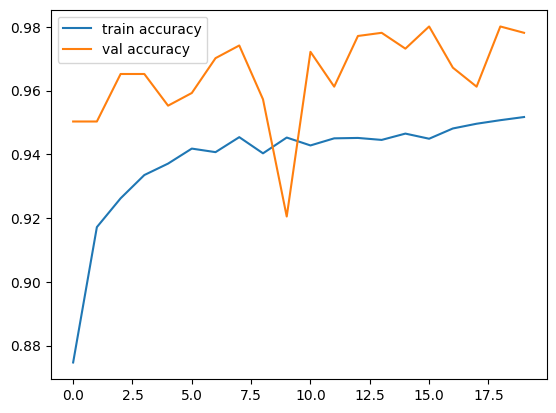

In [13]:
plt.plot(history.history['accuracy'],label = "train accuracy")
plt.plot(history.history['val_accuracy'],label = "val accuracy")
plt.legend()
plt.show()

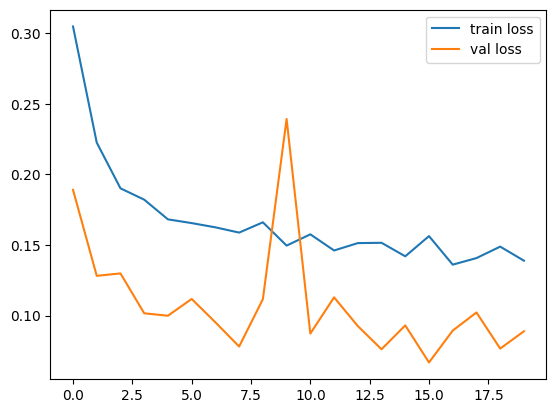

In [14]:
plt.plot(history.history['loss'],label = "train loss")
plt.plot(history.history['val_loss'],label = "val loss")
plt.legend()
plt.show()

In [28]:
prediction = model.predict(testing_set)
prediction

97/97 ━━━━━━━━━━━━━━━━━━━━ 33s 183ms/step


array([[6.7816787e-11],
       [4.6377936e-06],
       [1.8675259e-05],
       ...,
       [1.0000000e+00],
       [1.0000000e+00],
       [9.9988699e-01]], shape=(1550, 1), dtype=float32)

In [ ]:
true_prediction = (prediction >= 0.5).astype(int)

In [17]:
y_true = testing_set.classes

In [36]:
print(classification_report(y_true,true_prediction))
confusion_matrix(y_true,true_prediction)

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       800
           1       0.96      0.98      0.97       750

    accuracy                           0.97      1550
   macro avg       0.97      0.97      0.97      1550
weighted avg       0.97      0.97      0.97      1550



array([[771,  29],
       [ 16, 734]])

In [19]:
model.save("chest_x_ray_model.keras")

In [20]:
model = load_model("chest_x_ray_model.keras")

In [21]:
image_path = "../Datasets/normal.jpg"
prediction = image.load_img(image_path,target_size = (224,224))
prediction = image.img_to_array(prediction)

In [22]:
import numpy as np

In [23]:
prediction = np.expand_dims(prediction,axis=0)
prediction.shape

(1, 224, 224, 3)

In [24]:
prediction = preprocess_input(prediction)

In [25]:
pred_data = model.predict(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 15s 15s/step


In [ ]:
(pred_data >= 0.5).astype(int)

array([[0]])

In [ ]:
training_set.class_indices

{'ABNORMAL': 0, 'NORMAL': 1}